# Kidney Disease Dataset — Exploratory Data Analysis

**Dataset:** `kidney_disease.csv` — 400 patient records, 26 columns.
**Goal:** understand every column before building the ML model.

**This notebook covers, for each column:**
1. **mean / median / mode**
2. **null-value % + a suggested imputation action**
3. **data distribution + what the column means clinically**

> **Tooling constraint:** the analysis code below imports **only**
> `pandas`, `numpy`, `matplotlib` and `seaborn`. No scikit-learn, scipy or other helpers.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 3.6)
plt.rcParams["axes.titlesize"] = 12

## 2. Load the raw data

In [2]:
DATA_PATH = "kidney_disease.csv"
raw = pd.read_csv(DATA_PATH)
print(f"shape: {raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

shape: 400 rows x 26 columns


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.000,80.000,1.020,1.000,0.000,NaN,normal,notpresent,notpresent,121.000,36.000,1.200,NaN,NaN,15.400,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.000,50.000,1.020,4.000,0.000,NaN,normal,notpresent,notpresent,NaN,18.000,0.800,NaN,NaN,11.300,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.000,80.000,1.010,2.000,3.000,normal,normal,notpresent,notpresent,423.000,53.000,1.800,NaN,NaN,9.600,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.000,70.000,1.005,4.000,0.000,normal,abnormal,present,notpresent,117.000,56.000,3.800,111.000,2.500,11.200,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.000,80.000,1.010,2.000,0.000,normal,normal,notpresent,notpresent,106.000,26.000,1.400,NaN,NaN,11.600,35,7300,4.6,no,no,no,good,no,no,ckd


In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(),
})
overview

,dtype,non_null,missing,missing_%,unique
id,int64,400,0,0.000,400
age,float64,391,9,2.250,76
bp,float64,388,12,3.000,10
sg,float64,353,47,11.750,5
al,float64,354,46,11.500,6
su,float64,351,49,12.250,6
rbc,str,248,152,38.000,2
pc,str,335,65,16.250,2
pcc,str,396,4,1.000,2
ba,str,396,4,1.000,2


### 2.1 Data-quality checks before trusting any statistic

Several columns that *look* numeric (`pcv`, `wc`, `rc`) are stored as text, and a few
text columns carry hidden tabs/spaces or `?` sentinels. If we computed stats on the raw
frame these values would silently break the numeric summaries, so we detect and clean them first.

In [4]:
text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]

dirty = {}
for c in text_cols:
    s = raw[c].dropna().astype(str)
    tabs = int(s.str.contains("\t").sum())
    spaces = int((s != s.str.strip()).sum())
    questions = int((s.str.strip() == "?").sum())
    if tabs or spaces or questions:
        dirty[c] = {"tabs": tabs, "leading/trailing spaces": spaces, "'?' sentinel": questions}

pd.DataFrame(dirty).T

,tabs,leading/trailing spaces,'?' sentinel
pcv,2,2,1
wc,3,3,1
rc,1,1,1
dm,5,6,0
cad,2,2,0
classification,2,2,0


**What the check shows**

* `pcv`, `wc`, `rc` are strings and contain `\t?` / tab-prefixed numbers → must be coerced to numeric.
* `dm`, `cad`, `classification` contain tab- or space-padded labels (`\tno`, ` yes`, `ckd\t`) → must be stripped.
* These defects inflate the apparent "missing" count if handled naively, so the cleaning step
  below strips whitespace **first**, then converts sentinels to `NaN`.

## 3. Clean a working copy

The raw frame is kept untouched as `raw`; all analysis runs on `clean`.

In [5]:
clean = raw.copy()

# 1) strip tabs / spaces from every text column and normalise sentinels to NaN
text_cols = [c for c in clean.columns if not pd.api.types.is_numeric_dtype(clean[c])]
for c in text_cols:
    clean[c] = (clean[c].astype("string")
                .str.replace("\t", "", regex=False)
                .str.strip())
    clean[c] = clean[c].replace({"": pd.NA, "?": pd.NA, "nan": pd.NA})

# 2) columns stored as text that are actually numeric
for c in ["pcv", "wc", "rc"]:
    clean[c] = pd.to_numeric(clean[c], errors="coerce").astype("float64")

# 3) target: ckd -> 1, notckd -> 0, plus a readable label for plots
clean["classification"] = clean["classification"].map({"ckd": 1, "notckd": 0}).astype("int64")
clean["target"] = clean["classification"].map({0: "notckd", 1: "ckd"})

print("Cleaned dtypes:")
print(clean.dtypes.astype(str).to_string())
print("\nTarget distribution:")
print(clean["target"].value_counts().to_string())

Cleaned dtypes:
id                  int64
age               float64
bp                float64
sg                float64
al                float64
su                float64
rbc                string
pc                 string
pcc                string
ba                 string
bgr               float64
bu                float64
sc                float64
sod               float64
pot               float64
hemo              float64
pcv               float64
wc                float64
rc                float64
htn                string
dm                 string
cad                string
appet              string
pe                 string
ane                string
classification      int64
target                str

Target distribution:
target
ckd       250
notckd    150


In [6]:
missing_check = pd.DataFrame({
    "raw_missing": raw.isna().sum(),
    "clean_missing": clean[raw.columns].isna().sum(),
    "clean_missing_%": (clean[raw.columns].isna().mean() * 100).round(2),
})
missing_check = missing_check[missing_check["clean_missing"] > 0].sort_values(
    "clean_missing_%", ascending=False
)
missing_check

,raw_missing,clean_missing,clean_missing_%
rbc,152,152,38.000
rc,130,131,32.750
wc,105,106,26.500
pot,88,88,22.000
sod,87,87,21.750
pcv,70,71,17.750
pc,65,65,16.250
hemo,52,52,13.000
su,49,49,12.250
sg,47,47,11.750


The `raw_missing` vs `clean_missing` gap confirms the sentinels: e.g. `pcv` jumps from
70 → 71, `wc` from 105 → 106, `rc` from 130 → 131 missing values once `\t?` is treated as missing.

---
## 4. Column dictionary

`kind` distinguishes numeric measurements, ordinal grades, and binary clinical flags.
The `action` column is the recommended default imputation strategy — revisited after the
per-column distributions below.

In [7]:
COLUMN_INFO = {
    "id": dict(meaning="Unique row identifier (0–399).", kind="identifier",
               action="Drop — carries no clinical signal."),
    "age": dict(meaning="Age of the patient, in years.", kind="numeric",
                action="Median (2.25% missing; robust to the mild left skew)."),
    "bp": dict(meaning="Blood pressure, mm/Hg.", kind="numeric",
               action="Median (3.0% missing; right-skewed with a 180 outlier)."),
    "sg": dict(meaning="Urine specific gravity — urine concentration (1.005–1.025).", kind="ordinal numeric",
               action="Mode / median (11.75% missing; discrete ordinal)."),
    "al": dict(meaning="Albumin in urine, graded 0–5 (higher = more protein leakage).", kind="ordinal numeric",
               action="Mode = 0 (11.5% missing; zero-inflated ordinal)."),
    "su": dict(meaning="Sugar in urine, graded 0–5 (higher = more glycosuria).", kind="ordinal numeric",
               action="Mode = 0 (12.25% missing; zero-inflated ordinal)."),
    "rbc": dict(meaning="Red blood cells in urine: normal / abnormal.", kind="binary categorical",
                action="Mode + missing indicator (38% missing — too high to trust a single fill)."),
    "pc": dict(meaning="Pus cells in urine: normal / abnormal.", kind="binary categorical",
               action="Mode = normal (16.25% missing)."),
    "pcc": dict(meaning="Pus-cell clumps: present / notpresent.", kind="binary categorical",
                action="Mode = notpresent (1% missing)."),
    "ba": dict(meaning="Bacteria in urine: present / notpresent.", kind="binary categorical",
               action="Mode = notpresent (1% missing)."),
    "bgr": dict(meaning="Random blood glucose, mg/dL.", kind="numeric",
                action="Median (11% missing; strongly right-skewed)."),
    "bu": dict(meaning="Blood urea, mg/dL.", kind="numeric",
               action="Median (4.75% missing; right-skewed with extreme highs)."),
    "sc": dict(meaning="Serum creatinine, mg/dL — a key kidney-filtration marker.", kind="numeric",
               action="Median (4.25% missing; heavy right tail and outliers)."),
    "sod": dict(meaning="Serum sodium, mEq/L.", kind="numeric",
                action="Median (21.75% missing; verify the 4.5 entry first)."),
    "pot": dict(meaning="Serum potassium, mEq/L.", kind="numeric",
                action="Median (22% missing; verify the 47 entry first)."),
    "hemo": dict(meaning="Hemoglobin, g/dL.", kind="numeric",
                 action="Median (13% missing; mildly left-skewed)."),
    "pcv": dict(meaning="Packed cell volume, %.", kind="numeric (stored as text)",
                action="Median after coercion (17.75% missing; one '\t?' sentinel)."),
    "wc": dict(meaning="White blood-cell count, cells/cumm.", kind="numeric (stored as text)",
               action="Median after coercion (26.5% missing; skewed; one sentinel)."),
    "rc": dict(meaning="Red blood-cell count, millions/cmm.", kind="numeric (stored as text)",
               action="Median after coercion (32.75% missing; one sentinel)."),
    "htn": dict(meaning="Hypertension: yes / no.", kind="binary categorical",
                action="Mode = no (0.5% missing)."),
    "dm": dict(meaning="Diabetes mellitus: yes / no.", kind="binary categorical",
               action="Mode = no after stripping tabs/spaces (0.5% missing)."),
    "cad": dict(meaning="Coronary artery disease: yes / no.", kind="binary categorical",
                action="Mode = no (0.5% missing)."),
    "appet": dict(meaning="Appetite: good / poor.", kind="binary categorical",
                  action="Mode = good (0.25% missing)."),
    "pe": dict(meaning="Pedal edema (leg swelling): yes / no.", kind="binary categorical",
               action="Mode = no (0.25% missing)."),
    "ane": dict(meaning="Anemia: yes / no.", kind="binary categorical",
                action="Mode = no (0.25% missing)."),
    "classification": dict(meaning="Target label: ckd vs notckd.", kind="target",
                           action="No imputation — 0 missing (250 ckd / 150 notckd after cleaning)."),
}
info = pd.DataFrame(COLUMN_INFO).T.rename_axis("column")
info

,meaning,kind,action
column,,,
id,Unique row identifier (0–399).,identifier,Drop — carries no clinical signal.
age,"Age of the patient, in years.",numeric,Median (2.25% missing; robust to the mild left...
bp,"Blood pressure, mm/Hg.",numeric,Median (3.0% missing; right-skewed with a 180 ...
sg,Urine specific gravity — urine concentration (...,ordinal numeric,Mode / median (11.75% missing; discrete ordinal).
al,"Albumin in urine, graded 0–5 (higher = more pr...",ordinal numeric,Mode = 0 (11.5% missing; zero-inflated ordinal).
su,"Sugar in urine, graded 0–5 (higher = more glyc...",ordinal numeric,Mode = 0 (12.25% missing; zero-inflated ordinal).
rbc,Red blood cells in urine: normal / abnormal.,binary categorical,Mode + missing indicator (38% missing — too hi...
pc,Pus cells in urine: normal / abnormal.,binary categorical,Mode = normal (16.25% missing).
pcc,Pus-cell clumps: present / notpresent.,binary categorical,Mode = notpresent (1% missing).


**Column groups**

* **Numeric (14):** `age, bp, sg, al, su, bgr, bu, sc, sod, pot, hemo, pcv, wc, rc`
* **Binary categorical (10):** `rbc, pc, pcc, ba, htn, dm, cad, appet, pe, ane`
* **Identifier (1):** `id`
* **Target (1):** `classification`

## 5. Summary tables — all columns at once

### 5.1 Numeric columns

`mode` lists up to three values (ties are common for discrete measurements).
`iqr_outliers` counts values outside `Q1 − 1.5·IQR` / `Q3 + 1.5·IQR`.

In [8]:
NUM_COLS = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]


def null_pct(s):
    return round(s.isna().mean() * 100, 2)


def numeric_summary(col):
    s = clean[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return pd.Series({
        "count": int(s.notna().sum()),
        "null_%": null_pct(s),
        "mean": round(s.mean(), 3),
        "median": round(s.median(), 3),
        "mode": ", ".join(f"{m:g}" for m in s.mode().tolist()[:3]),
        "std": round(s.std(), 3),
        "skew": round(s.skew(), 3),
        "min": s.min(),
        "q1": q1,
        "q3": q3,
        "max": s.max(),
        "iqr_outliers": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
    }, name=col)


numeric_table = pd.DataFrame({c: numeric_summary(c) for c in NUM_COLS}).T
numeric_table.index.name = "column"
numeric_table

,count,null_%,mean,median,mode,std,skew,min,q1,q3,max,iqr_outliers
column,,,,,,,,,,,,
age,391,2.250,51.483,55.000,60,17.170,-0.668,2.000,42.000,64.500,90.000,10
bp,388,3.000,76.469,80.000,80,13.684,1.605,50.000,70.000,80.000,180.000,36
sg,353,11.750,1.017,1.020,1.02,0.006,-0.172,1.005,1.010,1.020,1.025,0
al,354,11.500,1.017,0.000,0,1.353,0.998,0.000,0.000,2.000,5.000,0
su,351,12.250,0.450,0.000,0,1.099,2.464,0.000,0.000,0.000,5.000,61
bgr,356,11.000,148.037,121.000,99,79.282,2.011,22.000,99.000,163.000,490.000,34
bu,381,4.750,57.426,42.000,46,50.503,2.634,1.500,27.000,66.000,391.000,38
sc,383,4.250,3.072,1.300,1.2,5.741,7.510,0.400,0.900,2.800,76.000,51
sod,313,21.750,137.529,138.000,135,10.409,-6.997,4.500,135.000,142.000,163.000,16


### 5.2 Categorical columns

For binary columns the label is mapped to `0/1`, so **`encoded_mean` is the prevalence of the
"positive" state** (`abnormal`, `present`, `yes`, `poor`). `encoded_median` is the 0/1 median.
Plain `mode` is the most frequent **label**.

In [9]:
CAT_COLS = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]

CAT_MAP = {
    "rbc": {"normal": 0, "abnormal": 1},
    "pc": {"normal": 0, "abnormal": 1},
    "pcc": {"notpresent": 0, "present": 1},
    "ba": {"notpresent": 0, "present": 1},
    "htn": {"no": 0, "yes": 1},
    "dm": {"no": 0, "yes": 1},
    "cad": {"no": 0, "yes": 1},
    "appet": {"good": 0, "poor": 1},
    "pe": {"no": 0, "yes": 1},
    "ane": {"no": 0, "yes": 1},
}


def categorical_summary(col):
    s = clean[col]
    enc = s.map(CAT_MAP[col])
    vc = s.value_counts(dropna=True)
    return pd.Series({
        "count": int(s.notna().sum()),
        "null_%": null_pct(s),
        "mode": vc.index[0],
        "mode_count": int(vc.iloc[0]),
        "encoded_mean": round(enc.mean(), 3),
        "encoded_median": enc.median(),
        "categories": ", ".join(f"{k}={v}" for k, v in vc.items()),
    }, name=col)


cat_table = pd.DataFrame({c: categorical_summary(c) for c in CAT_COLS}).T
cat_table.index.name = "column"
cat_table

,count,null_%,mode,mode_count,encoded_mean,encoded_median,categories
column,,,,,,,
rbc,248,38.000,normal,201,0.190,0.000,"normal=201, abnormal=47"
pc,335,16.250,normal,259,0.227,0.000,"normal=259, abnormal=76"
pcc,396,1.000,notpresent,354,0.106,0.000,"notpresent=354, present=42"
ba,396,1.000,notpresent,374,0.056,0.000,"notpresent=374, present=22"
htn,398,0.500,no,251,0.369,0.000,"no=251, yes=147"
dm,398,0.500,no,261,0.344,0.000,"no=261, yes=137"
cad,398,0.500,no,364,0.085,0.000,"no=364, yes=34"
appet,399,0.250,good,317,0.206,0.000,"good=317, poor=82"
pe,399,0.250,no,323,0.190,0.000,"no=323, yes=76"


## 6. Per-column analysis

Each cell prints the column's meaning, mean/median/mode, missingness, skew and outlier count,
then plots the **distribution** and a **boxplot** (numeric) or **count plots** (categorical,
split by target).

> For binary categorical columns `mean`/`median` are computed on the 0/1 encoding described above.

In [10]:
def analyze_numeric(col):
    s = clean[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    outliers = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    skew = s.skew()

    if skew > 0.5:
        shape = "right-skewed (long tail of high values)"
    elif skew < -0.5:
        shape = "left-skewed (long tail of low values)"
    else:
        shape = "roughly symmetric"

    print(f"{col.upper()} — {COLUMN_INFO[col]['meaning']}")
    print(f"  mean   = {s.mean():.3f}")
    print(f"  median = {s.median():.3f}")
    print(f"  mode   = {', '.join(f'{m:g}' for m in s.mode().tolist()[:3])}")
    print(f"  nulls  = {null_pct(s)}%   (n = {int(s.notna().sum())})")
    print(f"  std={s.std():.3f} | skew={skew:.2f} -> {shape}")
    print(f"  range  = [{s.min():g}, {s.max():g}] | IQR outliers = {outliers}")
    print(f"  suggested action: {COLUMN_INFO[col]['action']}")

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    sns.histplot(s.dropna(), kde=True, ax=axes[0], color="#4C72B0")
    axes[0].set_title(f"{col} — distribution (histogram + KDE)")
    axes[0].set_xlabel(col)
    sns.boxplot(x=s.dropna(), ax=axes[1], color="#55A868")
    axes[1].set_title(f"{col} — boxplot (outliers)")
    axes[1].set_xlabel(col)
    plt.tight_layout()
    plt.show()


def analyze_categorical(col):
    s = clean[col]
    enc = s.map(CAT_MAP[col])
    vc = s.value_counts(dropna=True)
    positive = [k for k, v in CAT_MAP[col].items() if v == 1][0]

    print(f"{col.upper()} — {COLUMN_INFO[col]['meaning']}")
    print(f"  mode   = {vc.index[0]} ({vc.iloc[0]} / {int(s.notna().sum())} = {vc.iloc[0] / s.notna().sum() * 100:.1f}%)")
    print(f"  mean   = {enc.mean():.3f}  (encoded 0/1; share that are '{positive}')")
    print(f"  median = {enc.median():g}  (encoded 0/1)")
    print(f"  nulls  = {null_pct(s)}%   (n = {int(s.notna().sum())})")
    print(f"  counts = {', '.join(f'{k}={v}' for k, v in vc.items())}")
    print(f"  suggested action: {COLUMN_INFO[col]['action']}")

    order = list(CAT_MAP[col].keys())
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    sns.countplot(data=clean, x=col, order=order, ax=axes[0], color="#4C72B0")
    axes[0].set_title(f"{col} — overall distribution")
    sns.countplot(data=clean, x=col, order=order, hue="target",
                  hue_order=["notckd", "ckd"], ax=axes[1])
    axes[1].set_title(f"{col} — split by target")
    plt.tight_layout()
    plt.show()

### 6.1 Numeric columns

#### `age`

AGE — Age of the patient, in years.
  mean   = 51.483
  median = 55.000
  mode   = 60
  nulls  = 2.25%   (n = 391)
  std=17.170 | skew=-0.67 -> left-skewed (long tail of low values)
  range  = [2, 90] | IQR outliers = 10
  suggested action: Median (2.25% missing; robust to the mild left skew).


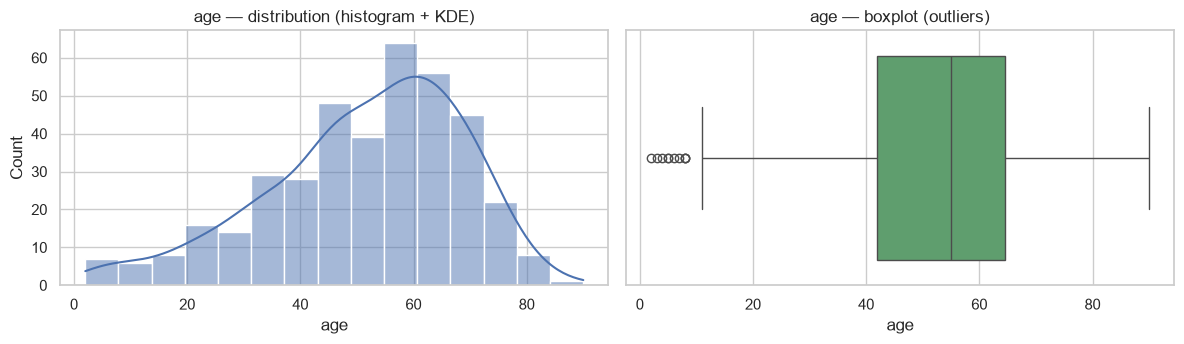

In [11]:
analyze_numeric("age")

#### `bp`

BP — Blood pressure, mm/Hg.
  mean   = 76.469
  median = 80.000
  mode   = 80
  nulls  = 3.0%   (n = 388)
  std=13.684 | skew=1.61 -> right-skewed (long tail of high values)
  range  = [50, 180] | IQR outliers = 36
  suggested action: Median (3.0% missing; right-skewed with a 180 outlier).


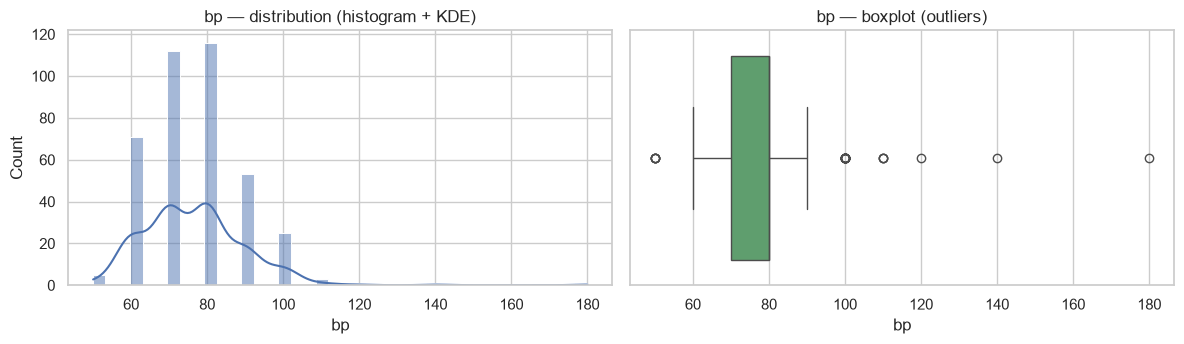

In [12]:
analyze_numeric("bp")

#### `sg`

SG — Urine specific gravity — urine concentration (1.005–1.025).
  mean   = 1.017
  median = 1.020
  mode   = 1.02
  nulls  = 11.75%   (n = 353)
  std=0.006 | skew=-0.17 -> roughly symmetric
  range  = [1.005, 1.025] | IQR outliers = 0
  suggested action: Mode / median (11.75% missing; discrete ordinal).


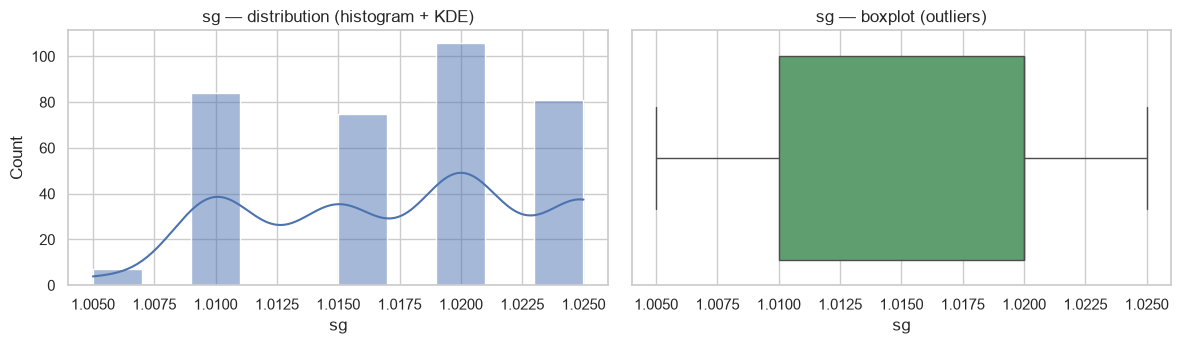

In [13]:
analyze_numeric("sg")

#### `al`

AL — Albumin in urine, graded 0–5 (higher = more protein leakage).
  mean   = 1.017
  median = 0.000
  mode   = 0
  nulls  = 11.5%   (n = 354)
  std=1.353 | skew=1.00 -> right-skewed (long tail of high values)
  range  = [0, 5] | IQR outliers = 0
  suggested action: Mode = 0 (11.5% missing; zero-inflated ordinal).


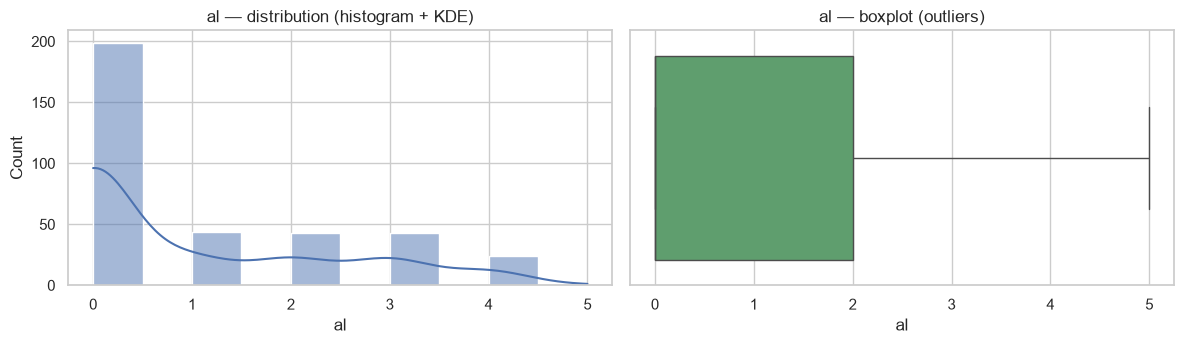

In [14]:
analyze_numeric("al")

#### `su`

SU — Sugar in urine, graded 0–5 (higher = more glycosuria).
  mean   = 0.450
  median = 0.000
  mode   = 0
  nulls  = 12.25%   (n = 351)
  std=1.099 | skew=2.46 -> right-skewed (long tail of high values)
  range  = [0, 5] | IQR outliers = 61
  suggested action: Mode = 0 (12.25% missing; zero-inflated ordinal).


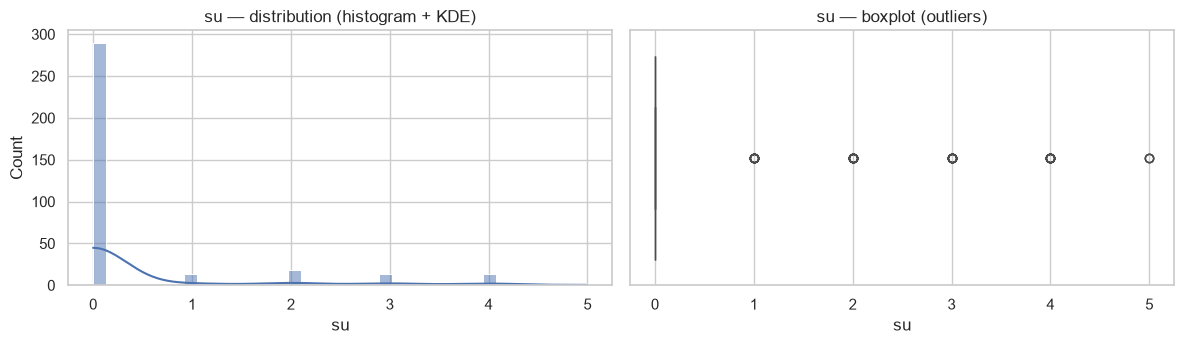

In [15]:
analyze_numeric("su")

#### `bgr`

BGR — Random blood glucose, mg/dL.
  mean   = 148.037
  median = 121.000
  mode   = 99
  nulls  = 11.0%   (n = 356)
  std=79.282 | skew=2.01 -> right-skewed (long tail of high values)
  range  = [22, 490] | IQR outliers = 34
  suggested action: Median (11% missing; strongly right-skewed).


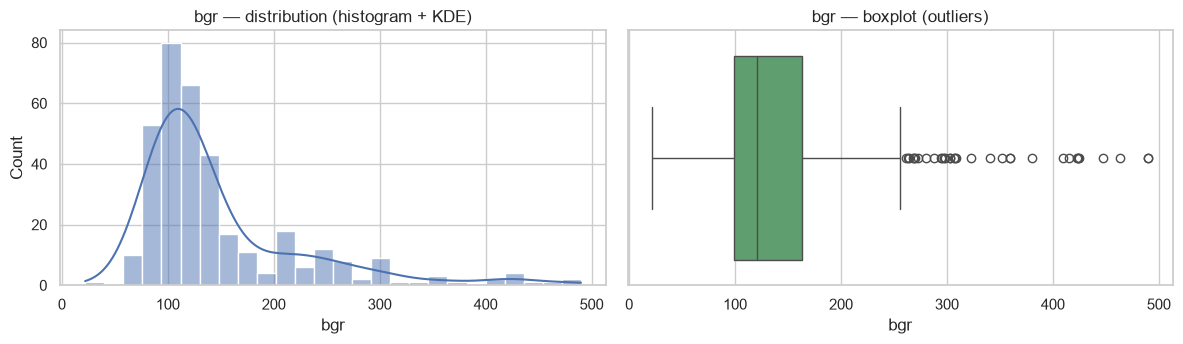

In [16]:
analyze_numeric("bgr")

#### `bu`

BU — Blood urea, mg/dL.
  mean   = 57.426
  median = 42.000
  mode   = 46
  nulls  = 4.75%   (n = 381)
  std=50.503 | skew=2.63 -> right-skewed (long tail of high values)
  range  = [1.5, 391] | IQR outliers = 38
  suggested action: Median (4.75% missing; right-skewed with extreme highs).


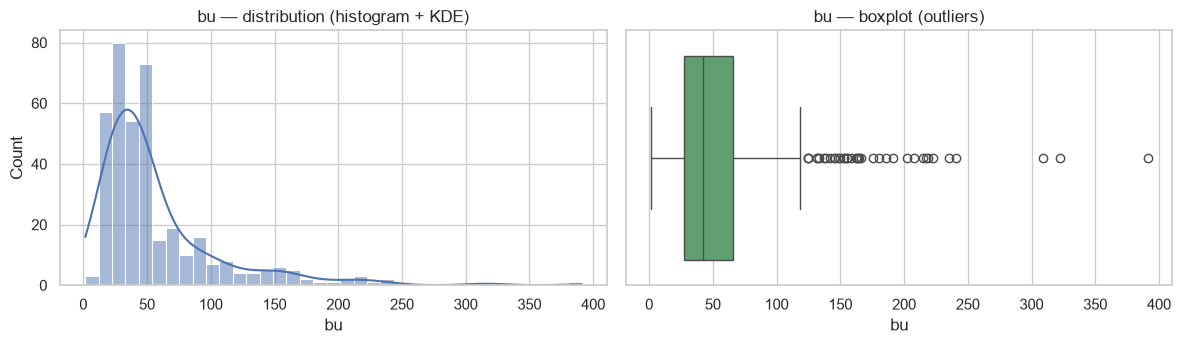

In [17]:
analyze_numeric("bu")

#### `sc`

SC — Serum creatinine, mg/dL — a key kidney-filtration marker.
  mean   = 3.072
  median = 1.300
  mode   = 1.2
  nulls  = 4.25%   (n = 383)
  std=5.741 | skew=7.51 -> right-skewed (long tail of high values)
  range  = [0.4, 76] | IQR outliers = 51
  suggested action: Median (4.25% missing; heavy right tail and outliers).


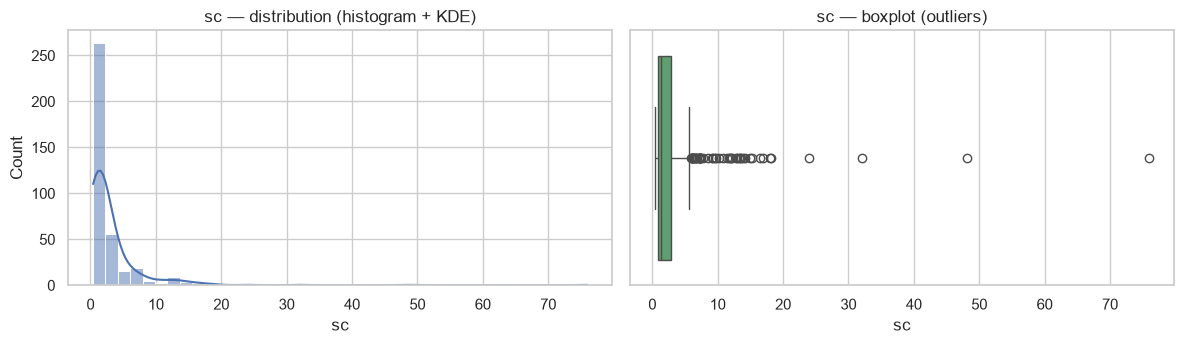

In [18]:
analyze_numeric("sc")

#### `sod`

SOD — Serum sodium, mEq/L.
  mean   = 137.529
  median = 138.000
  mode   = 135
  nulls  = 21.75%   (n = 313)
  std=10.409 | skew=-7.00 -> left-skewed (long tail of low values)
  range  = [4.5, 163] | IQR outliers = 16
  suggested action: Median (21.75% missing; verify the 4.5 entry first).


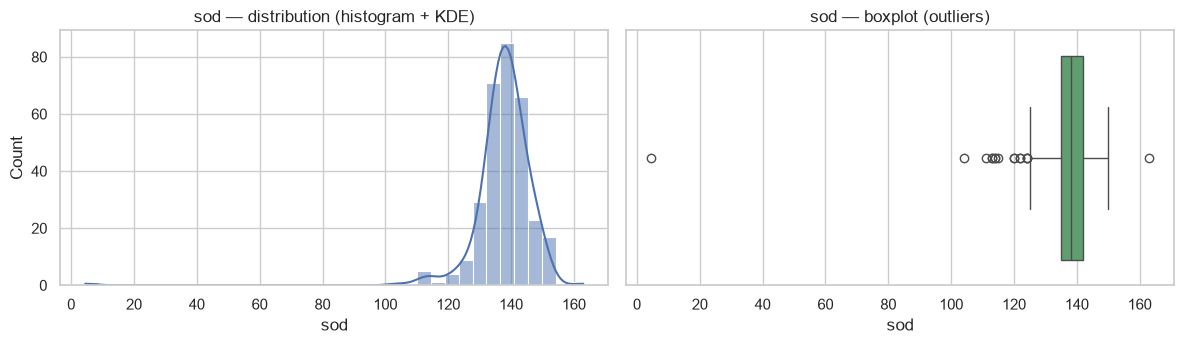

In [19]:
analyze_numeric("sod")

#### `pot`

POT — Serum potassium, mEq/L.
  mean   = 4.627
  median = 4.400
  mode   = 3.5, 5
  nulls  = 22.0%   (n = 312)
  std=3.194 | skew=11.58 -> right-skewed (long tail of high values)
  range  = [2.5, 47] | IQR outliers = 4
  suggested action: Median (22% missing; verify the 47 entry first).


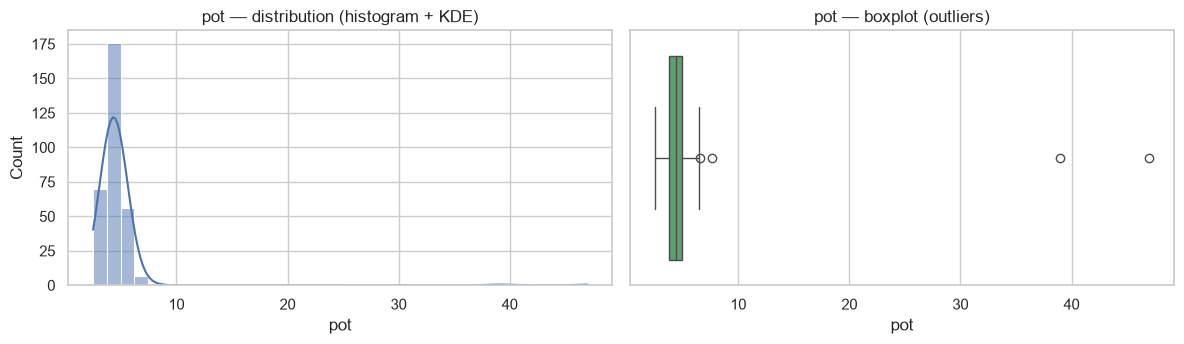

In [20]:
analyze_numeric("pot")

#### `hemo`

HEMO — Hemoglobin, g/dL.
  mean   = 12.526
  median = 12.650
  mode   = 15
  nulls  = 13.0%   (n = 348)
  std=2.913 | skew=-0.34 -> roughly symmetric
  range  = [3.1, 17.8] | IQR outliers = 1
  suggested action: Median (13% missing; mildly left-skewed).


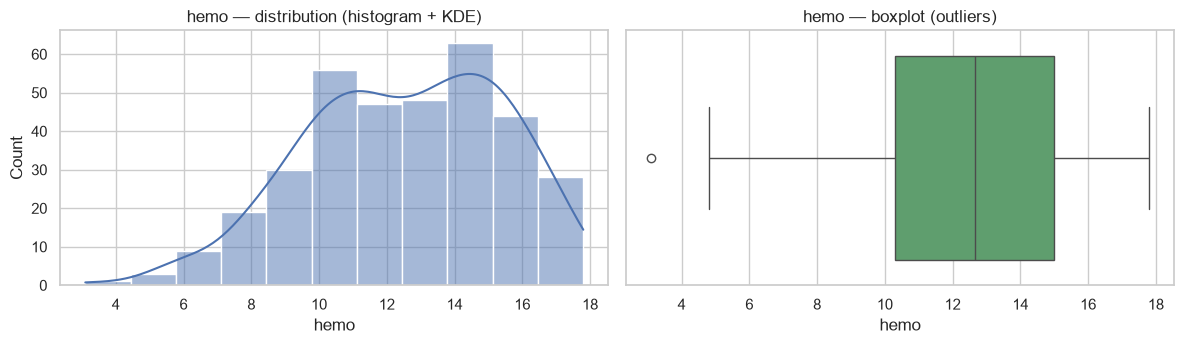

In [21]:
analyze_numeric("hemo")

#### `pcv`

PCV — Packed cell volume, %.
  mean   = 38.884
  median = 40.000
  mode   = 41, 52
  nulls  = 17.75%   (n = 329)
  std=8.990 | skew=-0.43 -> roughly symmetric
  range  = [9, 54] | IQR outliers = 1
  suggested action: Median after coercion (17.75% missing; one '	?' sentinel).


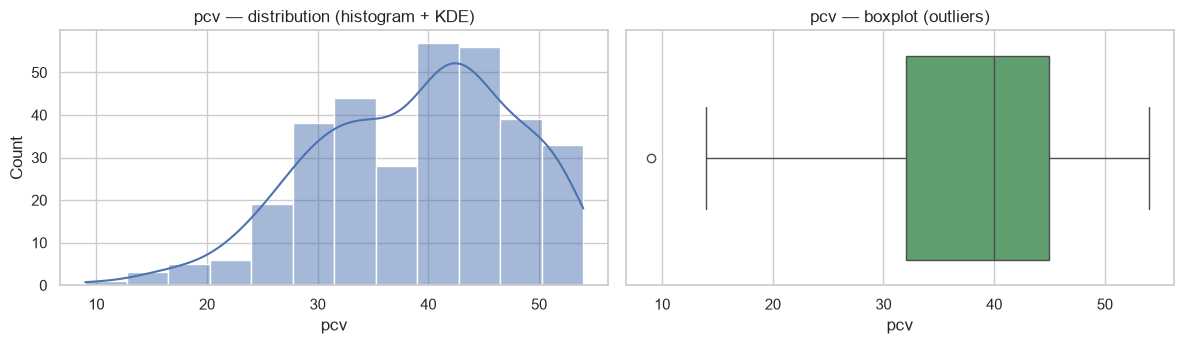

In [22]:
analyze_numeric("pcv")

#### `wc`

WC — White blood-cell count, cells/cumm.
  mean   = 8406.122
  median = 8000.000
  mode   = 9800
  nulls  = 26.5%   (n = 294)
  std=2944.474 | skew=1.62 -> right-skewed (long tail of high values)
  range  = [2200, 26400] | IQR outliers = 10
  suggested action: Median after coercion (26.5% missing; skewed; one sentinel).


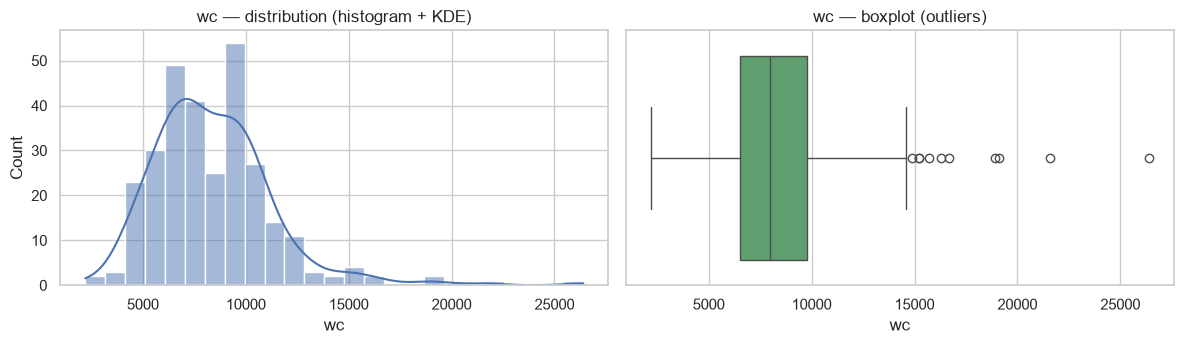

In [23]:
analyze_numeric("wc")

#### `rc`

RC — Red blood-cell count, millions/cmm.
  mean   = 4.707
  median = 4.800
  mode   = 5.2
  nulls  = 32.75%   (n = 269)
  std=1.025 | skew=-0.18 -> roughly symmetric
  range  = [2.1, 8] | IQR outliers = 1
  suggested action: Median after coercion (32.75% missing; one sentinel).


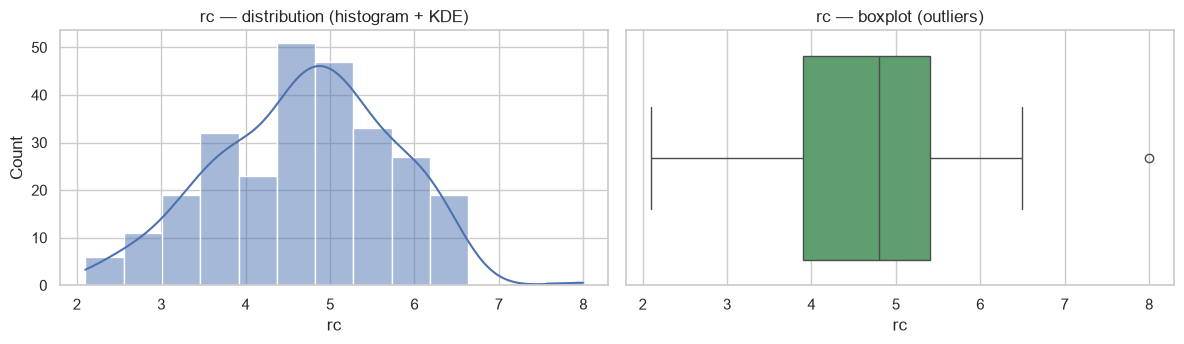

In [24]:
analyze_numeric("rc")

### 6.2 Categorical columns

#### `rbc`

RBC — Red blood cells in urine: normal / abnormal.
  mode   = normal (201 / 248 = 81.0%)
  mean   = 0.190  (encoded 0/1; share that are 'abnormal')
  median = 0  (encoded 0/1)
  nulls  = 38.0%   (n = 248)
  counts = normal=201, abnormal=47
  suggested action: Mode + missing indicator (38% missing — too high to trust a single fill).


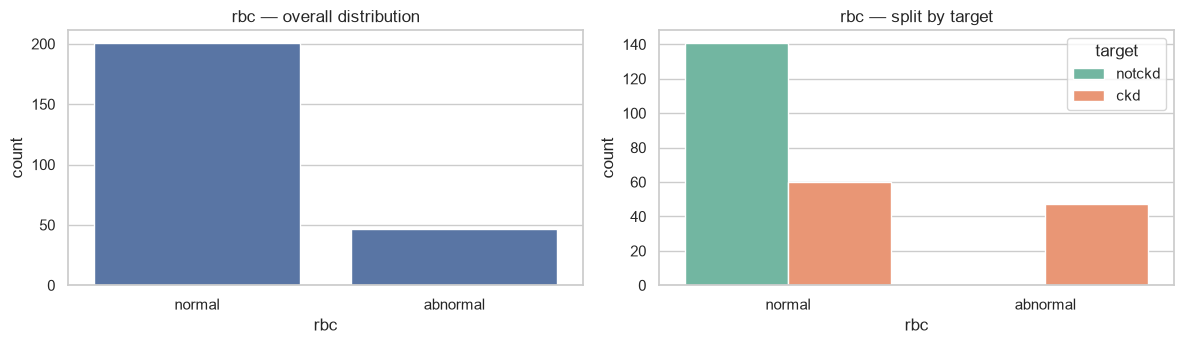

In [25]:
analyze_categorical("rbc")

#### `pc`

PC — Pus cells in urine: normal / abnormal.
  mode   = normal (259 / 335 = 77.3%)
  mean   = 0.227  (encoded 0/1; share that are 'abnormal')
  median = 0  (encoded 0/1)
  nulls  = 16.25%   (n = 335)
  counts = normal=259, abnormal=76
  suggested action: Mode = normal (16.25% missing).


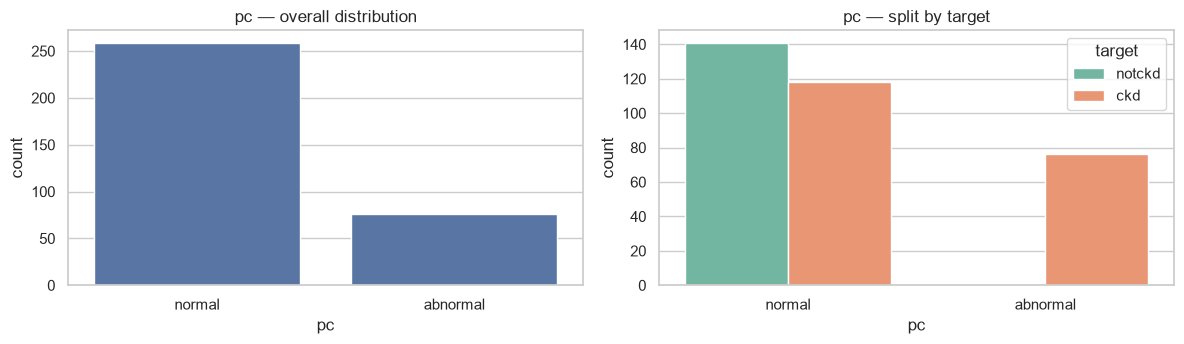

In [26]:
analyze_categorical("pc")

#### `pcc`

PCC — Pus-cell clumps: present / notpresent.
  mode   = notpresent (354 / 396 = 89.4%)
  mean   = 0.106  (encoded 0/1; share that are 'present')
  median = 0  (encoded 0/1)
  nulls  = 1.0%   (n = 396)
  counts = notpresent=354, present=42
  suggested action: Mode = notpresent (1% missing).


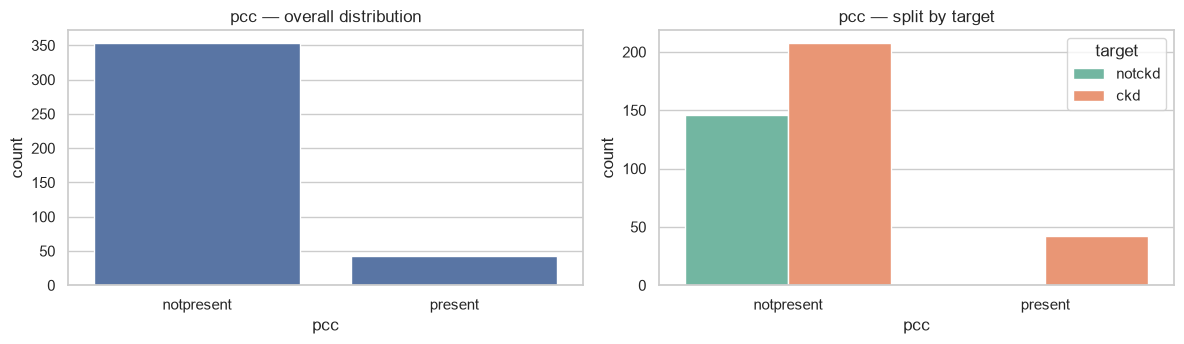

In [27]:
analyze_categorical("pcc")

#### `ba`

BA — Bacteria in urine: present / notpresent.
  mode   = notpresent (374 / 396 = 94.4%)
  mean   = 0.056  (encoded 0/1; share that are 'present')
  median = 0  (encoded 0/1)
  nulls  = 1.0%   (n = 396)
  counts = notpresent=374, present=22
  suggested action: Mode = notpresent (1% missing).


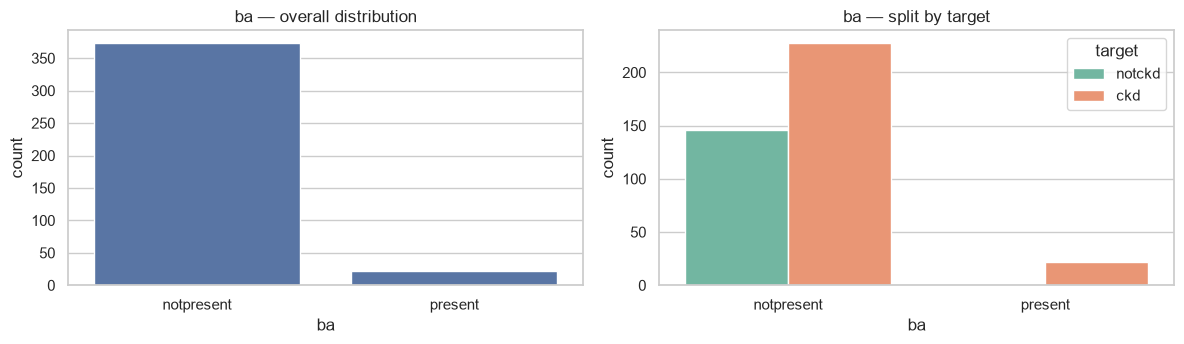

In [28]:
analyze_categorical("ba")

#### `htn`

HTN — Hypertension: yes / no.
  mode   = no (251 / 398 = 63.1%)
  mean   = 0.369  (encoded 0/1; share that are 'yes')
  median = 0  (encoded 0/1)
  nulls  = 0.5%   (n = 398)
  counts = no=251, yes=147
  suggested action: Mode = no (0.5% missing).


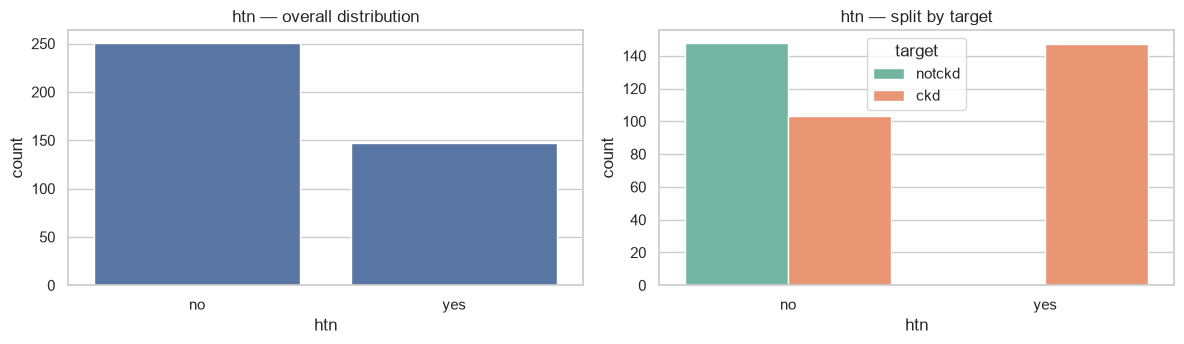

In [29]:
analyze_categorical("htn")

#### `dm`

DM — Diabetes mellitus: yes / no.
  mode   = no (261 / 398 = 65.6%)
  mean   = 0.344  (encoded 0/1; share that are 'yes')
  median = 0  (encoded 0/1)
  nulls  = 0.5%   (n = 398)
  counts = no=261, yes=137
  suggested action: Mode = no after stripping tabs/spaces (0.5% missing).


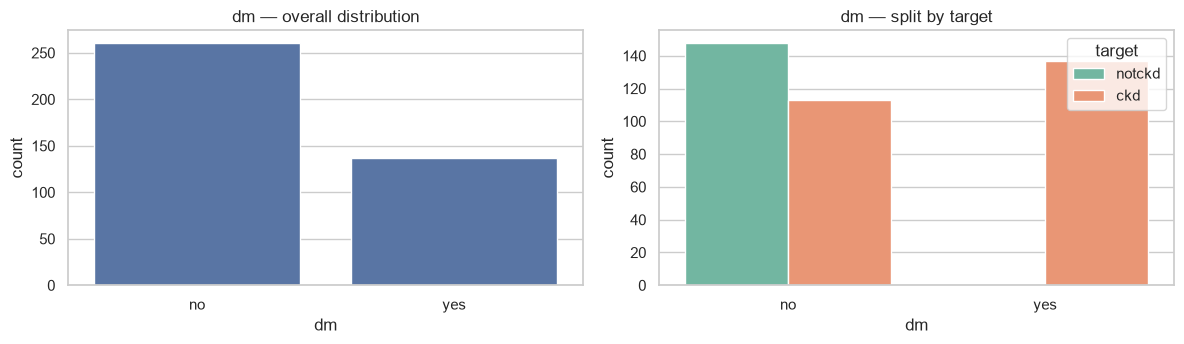

In [30]:
analyze_categorical("dm")

#### `cad`

CAD — Coronary artery disease: yes / no.
  mode   = no (364 / 398 = 91.5%)
  mean   = 0.085  (encoded 0/1; share that are 'yes')
  median = 0  (encoded 0/1)
  nulls  = 0.5%   (n = 398)
  counts = no=364, yes=34
  suggested action: Mode = no (0.5% missing).


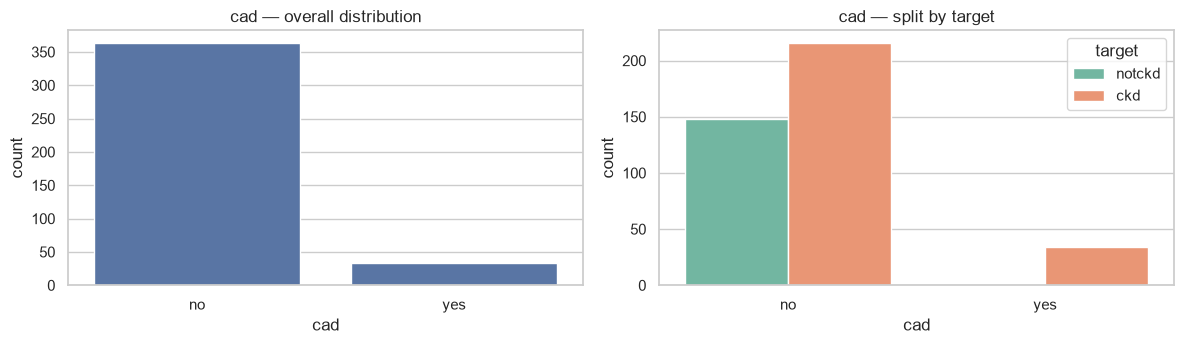

In [31]:
analyze_categorical("cad")

#### `appet`

APPET — Appetite: good / poor.
  mode   = good (317 / 399 = 79.4%)
  mean   = 0.206  (encoded 0/1; share that are 'poor')
  median = 0  (encoded 0/1)
  nulls  = 0.25%   (n = 399)
  counts = good=317, poor=82
  suggested action: Mode = good (0.25% missing).


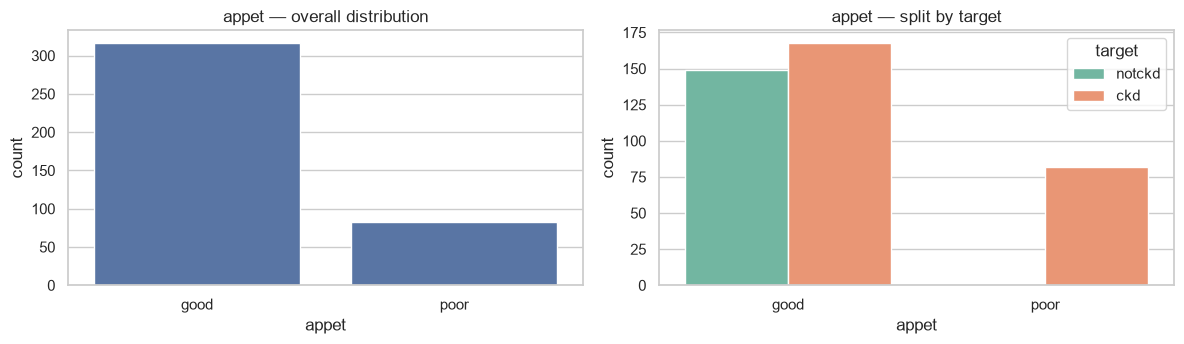

In [32]:
analyze_categorical("appet")

#### `pe`

PE — Pedal edema (leg swelling): yes / no.
  mode   = no (323 / 399 = 81.0%)
  mean   = 0.190  (encoded 0/1; share that are 'yes')
  median = 0  (encoded 0/1)
  nulls  = 0.25%   (n = 399)
  counts = no=323, yes=76
  suggested action: Mode = no (0.25% missing).


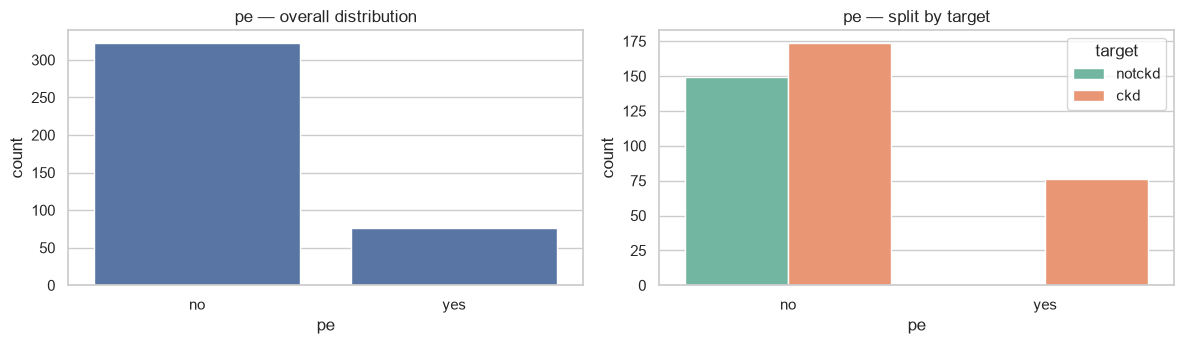

In [33]:
analyze_categorical("pe")

#### `ane`

ANE — Anemia: yes / no.
  mode   = no (339 / 399 = 85.0%)
  mean   = 0.150  (encoded 0/1; share that are 'yes')
  median = 0  (encoded 0/1)
  nulls  = 0.25%   (n = 399)
  counts = no=339, yes=60
  suggested action: Mode = no (0.25% missing).


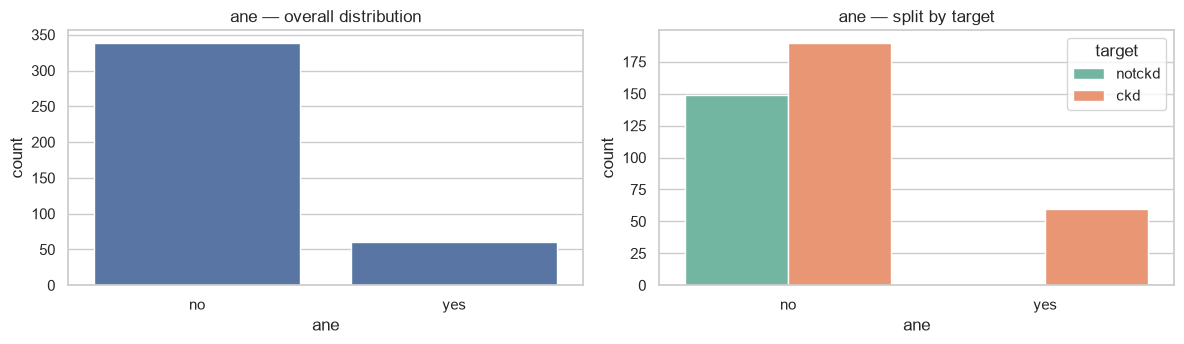

In [34]:
analyze_categorical("ane")

### 6.3 Identifier and target

#### `id`

ID — row identifier
  mean=199.5 | median=199.5 | mode=0, 1, 2
  nulls=0.0% | unique=400 of 400 rows | range=[0, 399]
  It is a simple 0..399 sequence, uniformly distributed and unrelated to the target.
  Suggested action: drop before modelling.


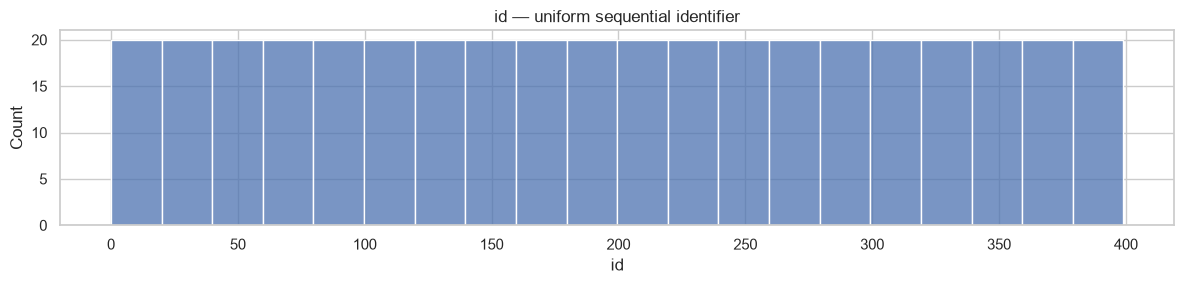

In [35]:
s = clean["id"]
print("ID — row identifier")
print(f"  mean={s.mean():.1f} | median={s.median():.1f} | mode={', '.join(f'{m:g}' for m in s.mode().tolist()[:3])}")
print(f"  nulls={null_pct(s)}% | unique={s.nunique()} of {len(s)} rows | range=[{s.min()}, {s.max()}]")
print("  It is a simple 0..399 sequence, uniformly distributed and unrelated to the target.")
print("  Suggested action: drop before modelling.")

plt.figure(figsize=(12, 3))
sns.histplot(s, bins=20, color="#4C72B0")
plt.title("id — uniform sequential identifier")
plt.xlabel("id")
plt.tight_layout()
plt.show()

#### `classification` (target)

CLASSIFICATION — target label
  mean   = 0.625  (share of ckd)
  median = 1
  mode   = ckd (250 rows)
  nulls  = 0.0%
  counts = notckd=150 (37.5%), ckd=250 (62.5%)


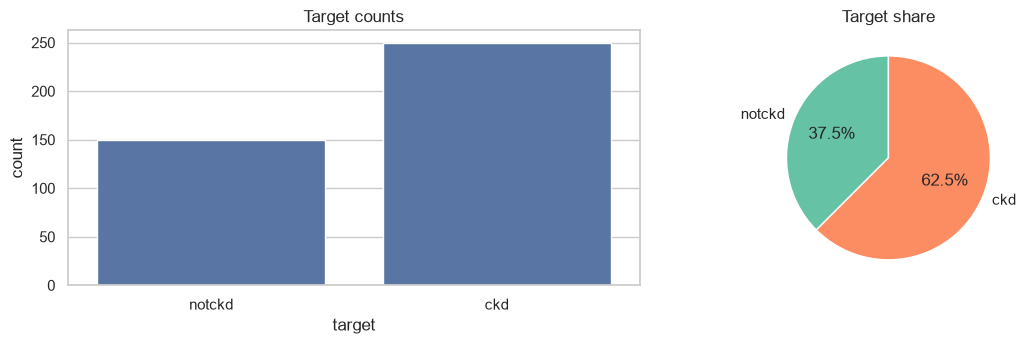

In [36]:
s = clean["classification"]
vc = clean["target"].value_counts().reindex(["notckd", "ckd"])
print("CLASSIFICATION — target label")
print(f"  mean   = {s.mean():.3f}  (share of ckd)")
print(f"  median = {s.median():g}")
print(f"  mode   = {vc.idxmax()} ({vc.max()} rows)")
print(f"  nulls  = {null_pct(s)}%")
print(f"  counts = {', '.join(f'{k}={v} ({v/len(s)*100:.1f}%)' for k, v in vc.items())}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
sns.countplot(data=clean, x="target", order=["notckd", "ckd"], ax=axes[0], color="#4C72B0")
axes[0].set_title("Target counts")
axes[1].pie(vc.values, labels=vc.index, autopct="%1.1f%%",
            colors=["#66C2A5", "#FC8D62"], startangle=90)
axes[1].set_title("Target share")
plt.tight_layout()
plt.show()

## 7. Missing-value plan (ranked)

Every column with at least one missing value, its rate, and the suggested handling.

In [37]:
plan = pd.DataFrame({
    "null_%": [null_pct(clean[c]) for c in raw.columns],
    "suggested_action": [COLUMN_INFO[c]["action"] for c in raw.columns],
}, index=raw.columns)
plan = plan[plan["null_%"] > 0].sort_values("null_%", ascending=False)
plan

,null_%,suggested_action
rbc,38.000,Mode + missing indicator (38% missing — too hi...
rc,32.750,Median after coercion (32.75% missing; one sen...
wc,26.500,Median after coercion (26.5% missing; skewed; ...
pot,22.000,Median (22% missing; verify the 47 entry first).
sod,21.750,Median (21.75% missing; verify the 4.5 entry f...
pcv,17.750,Median after coercion (17.75% missing; one '\t...
pc,16.250,Mode = normal (16.25% missing).
hemo,13.000,Median (13% missing; mildly left-skewed).
su,12.250,Mode = 0 (12.25% missing; zero-inflated ordinal).
sg,11.750,Mode / median (11.75% missing; discrete ordinal).


### 7.1 Is missingness related to the target?

This matters: if a column is missing mostly for one class, a plain mode/median fill can erase a
real signal. Rates are % missing **within** each class.

In [38]:
cols_with_missing = [c for c in raw.columns if clean[c].isna().any()]
miss_by_target = (clean[cols_with_missing].isna()
                  .groupby(clean["target"]).mean()
                  .mul(100).T.round(1))
miss_by_target

target,ckd,notckd
age,3.200,0.700
bp,4.000,1.300
sg,16.800,3.300
al,16.400,3.300
su,17.600,3.300
rbc,57.200,6.000
pc,22.400,6.000
pcc,0.000,2.700
ba,0.000,2.700
bgr,15.200,4.000


**Reading it:** `rbc` is missing for ~57% of CKD patients vs ~6% of non-CKD patients, and `pc`
shows a similar pattern — the missingness itself is informative (MNAR). For these columns it is
safer to **keep a `*_was_missing` flag** in addition to filling with the mode.

## 8. Suspicious values / likely data-entry errors

Values outside broad clinical plausibility ranges. These are flagged, **not** silently dropped —
verify with the data owner, then cap or correct.

In [39]:
RANGES = {
    "age": (1, 100), "bp": (40, 220), "sg": (1.000, 1.030), "al": (0, 5), "su": (0, 5),
    "bgr": (50, 500), "bu": (5, 300), "sc": (0.4, 20), "sod": (100, 160),
    "pot": (2, 8), "hemo": (3, 20), "pcv": (10, 60), "wc": (2000, 20000), "rc": (2, 8),
}

flags = []
for c, (lo, hi) in RANGES.items():
    bad = clean[(clean[c] < lo) | (clean[c] > hi)]
    if len(bad):
        flags.append({
            "column": c,
            "plausible_range": f"{lo:g}–{hi:g}",
            "n_outside": len(bad),
            "values": ", ".join(f"{v:g}" for v in sorted(bad[c].dropna().unique())),
        })
pd.DataFrame(flags).set_index("column")

,plausible_range,n_outside,values
column,,,
bgr,50–500,1,22
bu,5–300,4,"1.5, 309, 322, 391"
sc,0.4–20,4,"24, 32, 48.1, 76"
sod,100–160,2,"4.5, 163"
pot,2–8,2,"39, 47"
pcv,10–60,1,9
wc,2000–20000,2,"21600, 26400"


* `sod = 4.5` is almost certainly a typo (likely 145) and distorts the sodium mean/skew badly.
* `pot = 47` is almost certainly `4.7`.
* `sc = 76`, `bu = 391`, `wc = 26400`, `bgr = 22` are extreme but plausible at the tail of severe disease.
* Recommendation: correct obvious typos, then apply **winsorising / capping** at clinical limits
  (or use models insensitive to scale) rather than dropping rows.

## 9. Correlation overview (numeric + target)

A quick check of linear relationships and multicollinearity before modelling.

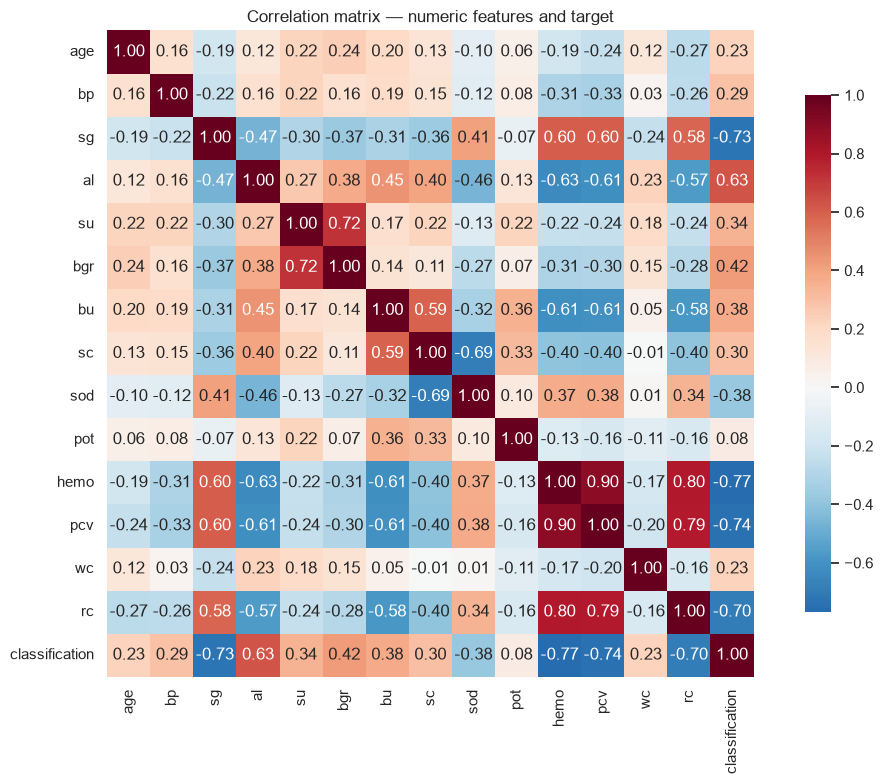

In [40]:
corr = clean[NUM_COLS + ["classification"]].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix — numeric features and target")
plt.tight_layout()
plt.show()

In [41]:
target_corr = (clean[NUM_COLS + ["classification"]].corr()["classification"]
               .drop("classification").sort_values())
target_corr.to_frame("correlation_with_ckd")

,correlation_with_ckd
hemo,-0.769
pcv,-0.741
sg,-0.732
rc,-0.699
sod,-0.376
pot,0.085
age,0.227
wc,0.232
bp,0.294
sc,0.300


## 10. Key findings & suggested next steps

### What the data says
* **Shape / target:** 400 rows, 26 columns. After cleaning the target is **250 CKD (62.5%) / 150 not-CKD (37.5%)** — moderately imbalanced.
* **Dirty columns:** `pcv`, `wc`, `rc` are text and need coercion; `dm`, `cad`, `classification` contain tab/space-padded labels. All handled in `clean`.
* **Missingness:** highest in `rbc` (38%), `rc` (32.75%), `wc` (26.5%), `pot` (22%), `sod` (21.75%), `pcv` (17.75%), `pc` (16.25%), `hemo` (13%).
* **Informative missingness:** `rbc`/`pc` are missing far more often among CKD patients, so add missing-value indicator flags instead of relying only on mode fills.
* **Strongest numeric signals for CKD:** `hemo` (−0.77), `pcv` (−0.74), `sg` (−0.73), `rc` (−0.70), `al` (+0.63), `bgr` (+0.42), `bu` (+0.38). Lower haemoglobin/packed-cell-volume/specific-gravity and higher albumin/glucose/urea point to CKD.
* **Multicollinearity:** `hemo`, `pcv` and `rc` are strongly inter-correlated — pick one or apply dimensionality reduction / regularisation.
* **Near-separating flags:** in this sample every `pcc`, `ba`, `htn`, `dm`, `cad`, `appet`, `pe`, `ane` positive case is CKD. Validate this on a hold-out split; it may be genuine, but such columns can dominate a model.
* **Distribution shapes:** most lab values (`bgr`, `bu`, `sc`, `su`, `bp`, `wc`) are right-skewed with outliers. Median imputation + scaling (or tree models) is appropriate; consider `log1p` for linear models.
* **Data errors:** `sod=4.5`, `pot=47` look like typos; `sc=76`, `bu=391`, `wc=26400` are extreme tails. Fix/cap before modelling.

### Recommended next steps
1. Correct the obvious typos, then cap/flag clinical outliers.
2. Impute numeric columns with the **median**, binary columns with the **mode** (add `*_missing` flags for `rbc`, `pc`, and possibly `rc`/`wc`).
3. Encode binary columns as 0/1; drop `id`.
4. Split **train/test before imputation/scaling** to avoid leakage, and evaluate with stratified CV.
5. Handle the 62.5/37.5 class imbalance (class weights / resampling) and compare a baseline logistic regression against a tree-based model.

> Waiting for the next steps from you — no model code has been written yet.